# Notebook 01: Microstructure Data Audit & Quality Verification

**Project:** QRD 2027: Liquidity-Adaptive Optimal Execution in Indian Equities  
**Asset:** RELIANCE (NSE Cash Segment)  
**Frequency:** 1-Minute OHLCV  
**Objective:** Execute the comprehensive 14-point microstructure validation suite, verify market hours and quote monotonicity, compute rolling volatility and liquidity regimes, and export publication-ready audit figures.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure project root is in sys.path (whether run from root or notebooks dir)
project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import get_config
from src.data_loader import (
    load_raw_data,
    process_ohlcv_pipeline,
    save_processed_data,
)
from src.data_audit import (
    run_comprehensive_audit,
    save_audit_report,
)
from src.calibration import (
    estimate_intraday_volume_profile,
    generate_calibration_summary,
    save_calibration_report,
)

# Apply clean publication style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
figures_dir = project_root / 'reports' / 'figures'
tables_dir = project_root / 'reports' / 'tables'
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)


## 1. Load System Configuration
Reading parameters from config/config.yaml using typed loader.


In [2]:
config = get_config(reload=True)
print(f'Project: {config.project.name} (v{config.project.version})')
print(f'Timezone: {config.data.timezone}')
print(f'Market Hours: {config.data.market_hours.start} to {config.data.market_hours.end} IST')
print(f'Stock Universe: {config.universe.stocks}')


Project: qrd2027_adaptive_execution (v0.1.0)
Timezone: Asia/Kolkata
Market Hours: 09:15 to 15:30 IST
Stock Universe: ['RELIANCE', 'HDFCBANK', 'ICICIBANK', 'INFY', 'TCS', 'SBIN', 'AXISBANK', 'KOTAKBANK', 'LT', 'ITC']


## 2. Load Sample Market Data
Loading raw 1-minute OHLCV sample for RELIANCE.


In [3]:
raw_data_path = project_root / 'data' / 'raw' / 'sample_RELIANCE_1min.csv'
df_raw = load_raw_data(raw_data_path)
print(f'Raw dataset loaded: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns')
df_raw.head()


Raw dataset loaded: 7,500 rows, 6 columns


,timestamp,open,high,low,close,volume
0,2024-01-01 09:15:00+0530,2850.13,2850.13,2845.10,2845.56,4177
1,2024-01-01 09:16:00+0530,2845.44,2848.76,2845.44,2847.39,4213
2,2024-01-01 09:17:00+0530,2847.28,2849.88,2847.28,2849.47,4062
3,2024-01-01 09:18:00+0530,2849.58,2849.58,2845.15,2846.00,4123
4,2024-01-01 09:19:00+0530,2846.23,2846.23,2843.86,2845.43,4143


## 3. Run Microstructure 14-Point Data Audit
Executing validation suite across price positivity, spread constraints, and session boundaries.


In [4]:
audit_report = run_comprehensive_audit(df_raw, file_path=str(raw_data_path), config=config)
save_audit_report(audit_report, output_dir=tables_dir)

print('=== DATA AUDIT SUMMARY ===')
for k, v in audit_report.summary.items():
    print(f'  {k}: {v}')

check_df = pd.DataFrame([{
    'Check': c.check_name,
    'Passed': c.passed,
    'Issues': c.issue_count,
    'Description': c.description
} for c in audit_report.checks])
check_df


=== DATA AUDIT SUMMARY ===
  total_records: 7500
  unique_days: 20
  total_checks: 14
  passed_checks: 13
  failed_checks_count: 1
  failed_checks: ['insufficient_trading_history']
  overall_status: FLAGGED


,Check,Passed,Issues,Description
0,missing_required_columns,True,0,Verify presence of mandatory OHLCV columns
1,duplicate_timestamps,True,0,Detect duplicate timestamps
2,non_monotonic_timestamps,True,0,Ensure timestamps are strictly ascending
3,missing_candles_in_session,True,0,Detect missing continuous 1-minute intervals (...
4,zero_or_negative_prices,True,0,Verify all price records are strictly positive...
5,negative_or_zero_volume,True,0,Verify volume is non-negative and track zero-v...
6,high_less_than_low,True,0,Verify High >= Low for every candle
7,open_close_outside_high_low,True,0,"Verify Open and Close are bounded within [Low,..."
8,extreme_returns,True,0,Flag 1-minute returns exceeding 10.0% threshold
9,insufficient_trading_history,False,100,Verify historical length meets minimum thresho...


## 4. Display Missing-Value & Integrity Summary


In [5]:
missing_summary = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Null Count': df_raw.isnull().sum(),
    'Null Pct (%)': (df_raw.isnull().sum() / len(df_raw)) * 100,
    'Unique Count': df_raw.nunique()
})
missing_summary


,Data Type,Null Count,Null Pct (%),Unique Count
timestamp,object,0,0.0,7500
open,float64,0,0.0,5939
high,float64,0,0.0,5936
low,float64,0,0.0,5926
close,float64,0,0.0,5891
volume,int64,0,0.0,2595


## 5. Execute Ingestion & Feature Augmentation Pipeline
Regularizing intraday timestamps, computing log returns, realized volatility, and assigning regimes.


In [6]:
processed_path = project_root / 'data' / 'processed' / 'RELIANCE_1min.parquet'
df_proc = process_ohlcv_pipeline(raw_data_path, config=config, output_path=processed_path)
print(f'Processed data saved to {processed_path}: {df_proc.shape[0]:,} rows')
df_proc[['timestamp', 'close', 'returns', 'realised_volatility', 'volatility_regime', 'liquidity_regime']].head(8)


Processed data saved to C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\data\processed\RELIANCE_1min.parquet: 7,500 rows


,timestamp,close,returns,realised_volatility,volatility_regime,liquidity_regime
0,2024-01-01 09:15:00+05:30,2845.56,0.000000,0.22283,stressed,high
1,2024-01-01 09:16:00+05:30,2847.39,0.000643,0.22283,stressed,high
2,2024-01-01 09:17:00+05:30,2849.47,0.000730,0.22283,stressed,high
3,2024-01-01 09:18:00+05:30,2846.00,-0.001219,0.22283,stressed,high
4,2024-01-01 09:19:00+05:30,2845.43,-0.000200,0.22283,stressed,high
5,2024-01-01 09:20:00+05:30,2844.81,-0.000218,0.22283,stressed,high
6,2024-01-01 09:21:00+05:30,2842.46,-0.000826,0.22283,stressed,high
7,2024-01-01 09:22:00+05:30,2841.16,-0.000457,0.22283,stressed,high


## 6. Plot Closing Prices (1-Minute Continuous)


Saved: C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\reports\figures\01_closing_prices.png


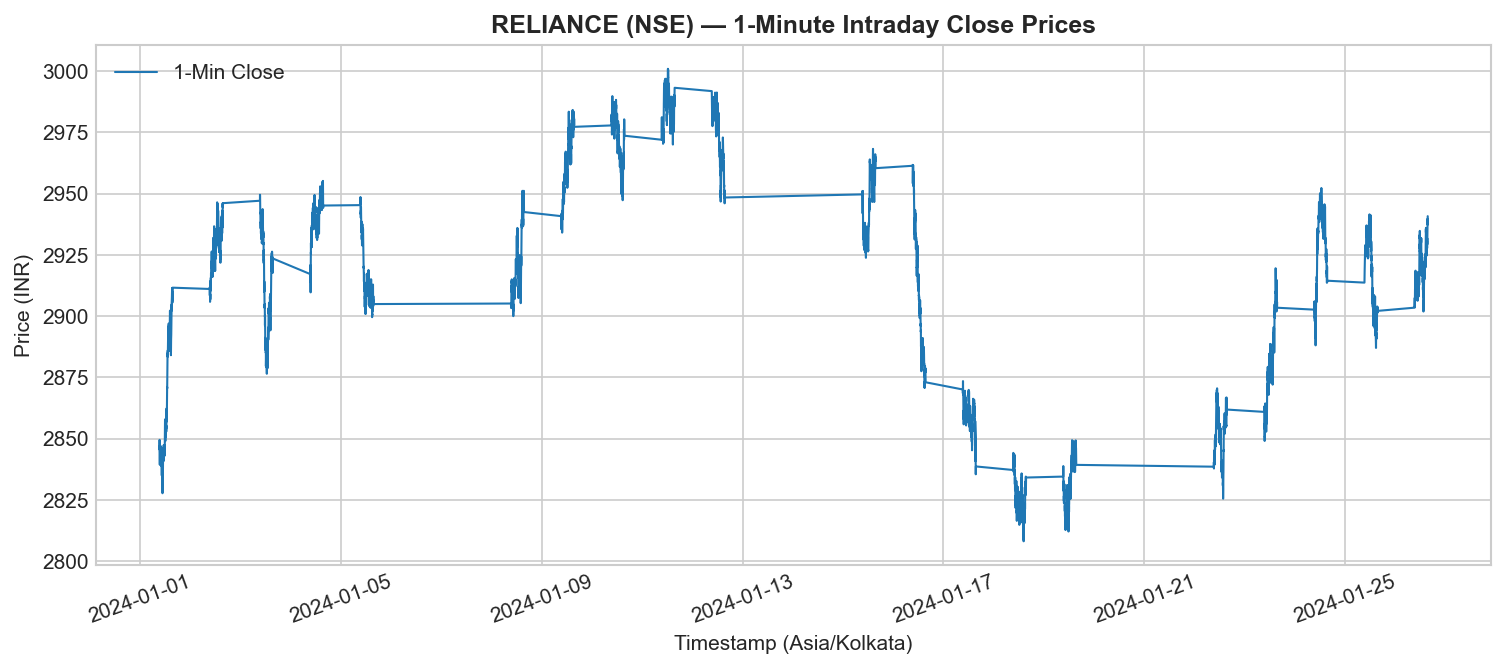

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5), dpi=150)
ax.plot(df_proc['timestamp'], df_proc['close'], color='#1f77b4', linewidth=1.0, label='1-Min Close')
ax.set_title('RELIANCE (NSE) — 1-Minute Intraday Close Prices', fontsize=12, fontweight='bold')
ax.set_xlabel('Timestamp (Asia/Kolkata)', fontsize=10)
ax.set_ylabel('Price (INR)', fontsize=10)
ax.legend(loc='upper left')
plt.xticks(rotation=20)
fig_path = figures_dir / '01_closing_prices.png'
fig.savefig(fig_path, bbox_inches='tight', dpi=300)
print(f'Saved: {fig_path}')
plt.show()


## 7. Plot Aggregated Daily Traded Volume


Saved: C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\reports\figures\02_daily_volume.png


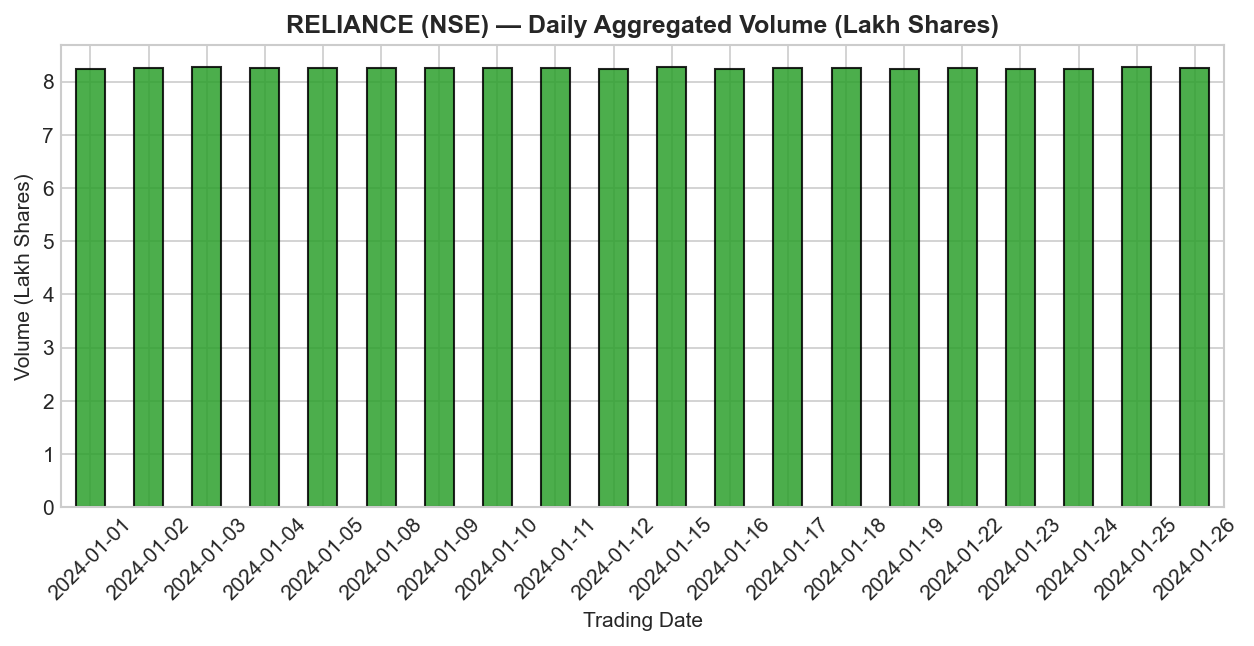

In [8]:
daily_vol = df_proc.groupby(df_proc['timestamp'].dt.date)['volume'].sum() / 1e5
fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
daily_vol.plot(kind='bar', ax=ax, color='#2ca02c', edgecolor='black', alpha=0.85)
ax.set_title('RELIANCE (NSE) — Daily Aggregated Volume (Lakh Shares)', fontsize=12, fontweight='bold')
ax.set_xlabel('Trading Date', fontsize=10)
ax.set_ylabel('Volume (Lakh Shares)', fontsize=10)
plt.xticks(rotation=45)
fig_path = figures_dir / '02_daily_volume.png'
fig.savefig(fig_path, bbox_inches='tight', dpi=300)
print(f'Saved: {fig_path}')
plt.show()


## 8. Plot Empirical Intraday Volume Profile (30-Minute Smile)
Empirical volume distribution across 13 30-minute buckets over the 09:15-15:30 IST session.


Saved: C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\reports\figures\03_intraday_volume_profile.png


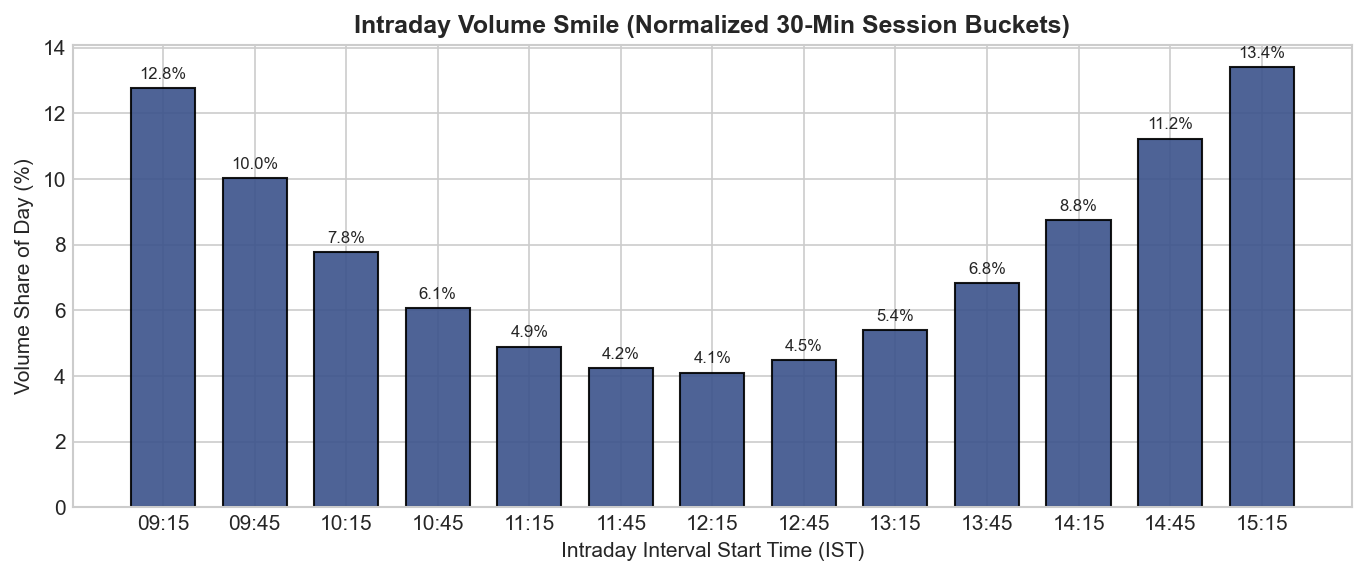

In [9]:
vol_profile = estimate_intraday_volume_profile(df_proc, num_buckets=config.calibration.volume_profile_buckets)
bucket_labels = [
    '09:15', '09:45', '10:15', '10:45', '11:15', '11:45',
    '12:15', '12:45', '13:15', '13:45', '14:15', '14:45', '15:15'
]
percentages = [vol_profile.buckets_30m[k] * 100 for k in sorted(vol_profile.buckets_30m.keys())]

fig, ax = plt.subplots(figsize=(11, 4), dpi=150)
bars = ax.bar(bucket_labels, percentages, color='#3b528b', edgecolor='black', alpha=0.9, width=0.7)
ax.set_title('Intraday Volume Smile (Normalized 30-Min Session Buckets)', fontsize=12, fontweight='bold')
ax.set_xlabel('Intraday Interval Start Time (IST)', fontsize=10)
ax.set_ylabel('Volume Share of Day (%)', fontsize=10)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=8)

fig_path = figures_dir / '03_intraday_volume_profile.png'
fig.savefig(fig_path, bbox_inches='tight', dpi=300)
print(f'Saved: {fig_path}')
plt.show()


## 9. Plot Rolling Realized Volatility (Annualized)


Saved: C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\reports\figures\04_rolling_volatility.png


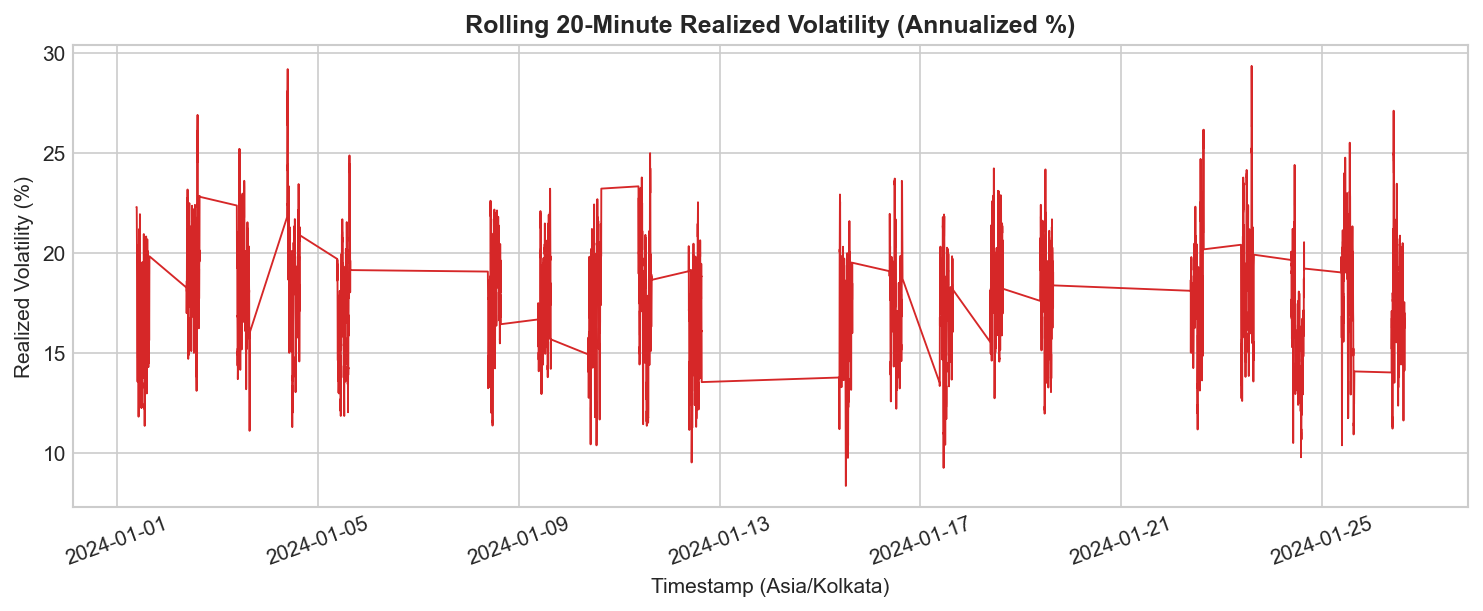

In [10]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=150)
ax.plot(df_proc['timestamp'], df_proc['realised_volatility'] * 100, color='#d62728', linewidth=0.9)
ax.set_title('Rolling 20-Minute Realized Volatility (Annualized %)', fontsize=12, fontweight='bold')
ax.set_xlabel('Timestamp (Asia/Kolkata)', fontsize=10)
ax.set_ylabel('Realized Volatility (%)', fontsize=10)
plt.xticks(rotation=20)
fig_path = figures_dir / '04_rolling_volatility.png'
fig.savefig(fig_path, bbox_inches='tight', dpi=300)
print(f'Saved: {fig_path}')
plt.show()


## 10. Plot Volatility & Liquidity Regime Distributions


Saved: C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\reports\figures\05_volatility_regimes.png


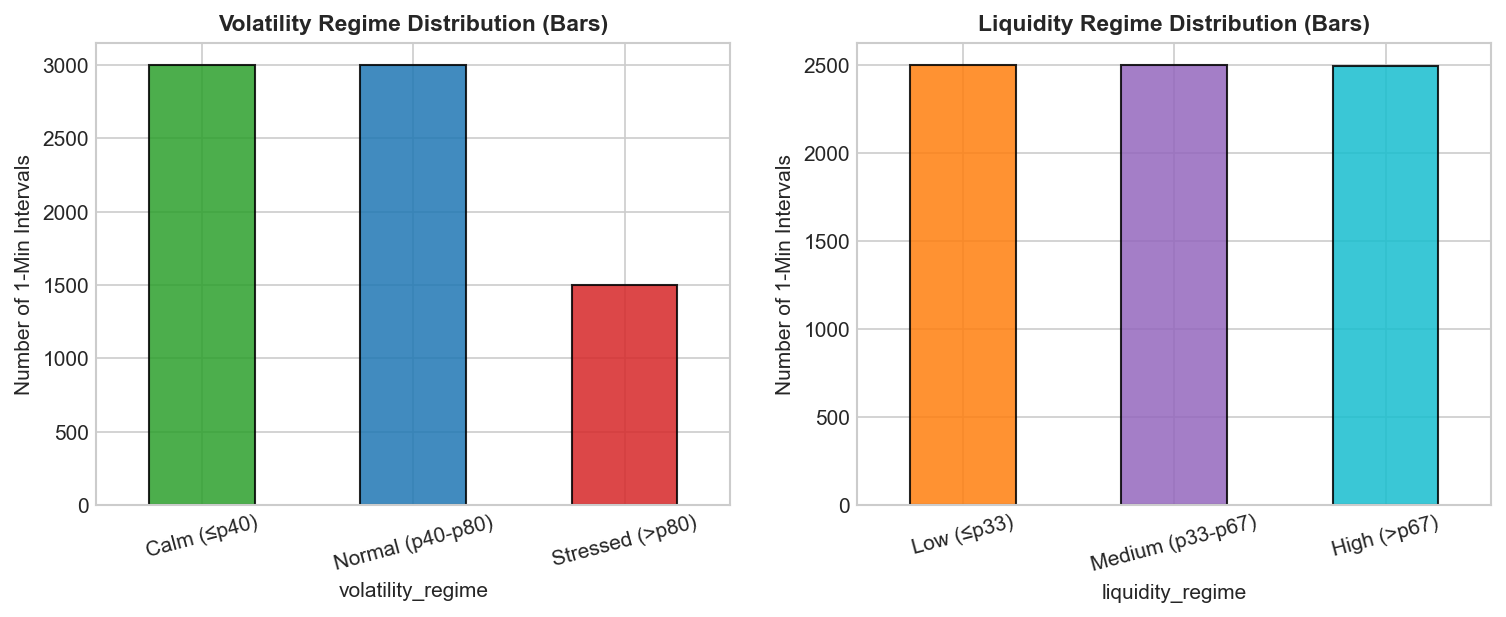

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=150)

# Volatility Regime Bar
vol_counts = df_proc['volatility_regime'].value_counts()[['calm', 'normal', 'stressed']]
vol_counts.plot(kind='bar', ax=axes[0], color=['#2ca02c', '#1f77b4', '#d62728'], edgecolor='black', alpha=0.85)
axes[0].set_title('Volatility Regime Distribution (Bars)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Number of 1-Min Intervals', fontsize=10)
axes[0].set_xticklabels(['Calm (≤p40)', 'Normal (p40-p80)', 'Stressed (>p80)'], rotation=15)

# Liquidity Regime Bar
liq_counts = df_proc['liquidity_regime'].value_counts()[['low', 'medium', 'high']]
liq_counts.plot(kind='bar', ax=axes[1], color=['#ff7f0e', '#9467bd', '#17becf'], edgecolor='black', alpha=0.85)
axes[1].set_title('Liquidity Regime Distribution (Bars)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Number of 1-Min Intervals', fontsize=10)
axes[1].set_xticklabels(['Low (≤p33)', 'Medium (p33-p67)', 'High (>p67)'], rotation=15)

fig_path_vol = figures_dir / '05_volatility_regimes.png'
fig.savefig(fig_path_vol, bbox_inches='tight', dpi=300)
print(f'Saved: {fig_path_vol}')
plt.show()


## 11. Generate Empirical Calibration Report
Calibrating ADV, spread, depth, and impact parameters and writing JSON report to 
eports/tables/calibration_report.json.


In [12]:
calib_report = generate_calibration_summary(df_proc, ticker='RELIANCE', config=config)
calib_path = save_calibration_report(calib_report, output_dir=tables_dir, format_type='json')
print(f'Calibration report generated and saved to {calib_path}')
print(f'ADV (Mean): {calib_report.average_daily_volume:,.0f} shares')
print(f'Daily Turnover: {calib_report.average_daily_turnover_inr / 1e7:.2f} Crore INR')
print(f'Assumed Baseline Spread: {calib_report.simulation_assumptions.assumed_baseline_spread_bps:.1f} bps')
print(f'Assumed Depth Multiplier: {calib_report.simulation_assumptions.assumed_depth_multiplier * 100:.1f}%')
print(f'Assumed Temporary Impact (eta): {calib_report.simulation_assumptions.assumed_temporary_impact_eta}')
print(f'Assumed Permanent Impact (gamma): {calib_report.simulation_assumptions.assumed_permanent_impact_fraction_gamma}')
print(f'Programmatic Itemized Cost: {calib_report.simulation_assumptions.transaction_cost_schedule.get("total_itemized_bps")} bps')


Calibration report generated and saved to C:\Users\Prathmesh Bunde\qrd2027_adaptive_execution\reports\tables\calibration_report.json
ADV (Mean): 825,214 shares
Daily Turnover: 240.35 Crore INR
Assumed Baseline Spread: 5.0 bps
Assumed Depth Multiplier: 5.0%
Assumed Temporary Impact (eta): 0.5
Assumed Permanent Impact (gamma): 0.1
Programmatic Itemized Cost: 6.1653 bps
